# **Preprocessing**

In [4]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
#Identify missing values
# Remove or replace missing values


df = pd.read_excel("data.xlsx")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())


First 5 rows:
  Company       Date  Close/Last    Volume    Open      High     Low
0    AAPL 2023-07-17      193.99  50520160  191.90  194.3200  191.81
1    AAPL 2023-07-14      190.69  41616240  190.23  191.1799  189.63
2    AAPL 2023-07-13      190.54  41342340  190.50  191.1900  189.78
3    AAPL 2023-07-12      189.77  60750250  189.68  191.7000  188.47
4    AAPL 2023-07-11      188.08  46638120  189.16  189.3000  186.60

Dataset shape:
(25160, 7)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25160 entries, 0 to 25159
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Company     25160 non-null  object        
 1   Date        25160 non-null  datetime64[ns]
 2   Close/Last  25160 non-null  float64       
 3   Volume      25160 non-null  int64         
 4   Open        25160 non-null  float64       
 5   High        25160 non-null  float64       
 6   Low         25160 non-null 

In [6]:

# Remove dollar signs and convert prices to numbers

price_columns = ["Close/Last", "Open", "High", "Low"]

for col in price_columns:
    df[col] = df[col].replace(r"[$,]", "", regex=True).astype(float)

# Display the cleaned price columns
print(df[price_columns].head())

# Check the data types
print("\nUpdated data types:")
print(df[price_columns].dtypes)


   Close/Last    Open      High     Low
0      193.99  191.90  194.3200  191.81
1      190.69  190.23  191.1799  189.63
2      190.54  190.50  191.1900  189.78
3      189.77  189.68  191.7000  188.47
4      188.08  189.16  189.3000  186.60

Updated data types:
Close/Last    float64
Open          float64
High          float64
Low           float64
dtype: object


This step identifies possible outliers in the four price columns; it does not delete anything.


In [7]:

# Detect possible outliers using the IQR method

price_columns = ["Close/Last", "Open", "High", "Low"]

for col in price_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(f"\nColumn: {col}")
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of possible outliers:", len(outliers))



Column: Close/Last
Lower limit: -109.93378750000002
Upper limit: 280.73631250000005
Number of possible outliers: 1902

Column: Open
Lower limit: -110.21125
Upper limit: 281.03875
Number of possible outliers: 1892

Column: High
Lower limit: -112.12528749999997
Upper limit: 285.2488125
Number of possible outliers: 1895

Column: Low
Lower limit: -108.67
Upper limit: 277.45799999999997
Number of possible outliers: 1873


We should check each company's prices separately. That gives us a more meaningful comparison.

In [8]:

# Check possible outliers separately for each company

price_columns = ["Close/Last", "Open", "High", "Low"]

for company, group in df.groupby("Company"):
    for col in price_columns:
        Q1 = group[col].quantile(0.25)
        Q3 = group[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR

        count = (
            (group[col] < lower_limit) |
            (group[col] > upper_limit)
        ).sum()

        print(company, "-", col, ":", count, "possible outliers")


AAPL - Close/Last : 0 possible outliers
AAPL - Open : 0 possible outliers
AAPL - High : 0 possible outliers
AAPL - Low : 0 possible outliers
AMD - Close/Last : 0 possible outliers
AMD - Open : 0 possible outliers
AMD - High : 0 possible outliers
AMD - Low : 0 possible outliers
AMZN - Close/Last : 0 possible outliers
AMZN - Open : 0 possible outliers
AMZN - High : 0 possible outliers
AMZN - Low : 0 possible outliers
CSCO - Close/Last : 0 possible outliers
CSCO - Open : 0 possible outliers
CSCO - High : 0 possible outliers
CSCO - Low : 0 possible outliers
META - Close/Last : 54 possible outliers
META - Open : 52 possible outliers
META - High : 49 possible outliers
META - Low : 55 possible outliers
MSFT - Close/Last : 0 possible outliers
MSFT - Open : 0 possible outliers
MSFT - High : 0 possible outliers
MSFT - Low : 0 possible outliers
NFLX - Close/Last : 0 possible outliers
NFLX - Open : 0 possible outliers
NFLX - High : 0 possible outliers
NFLX - Low : 0 possible outliers
QCOM - Close/

this shows possible outliers in the Open, High, and Low columns for META and TSLA.

TO CHNAGE DATES COLUMES INTO PERFECT


In [9]:

# Display some dates from the original Excel file

original_df = pd.read_excel("data.xlsx")

print(original_df["Date"].head(15))

0    2023-07-17
1    2023-07-14
2    2023-07-13
3    2023-07-12
4    2023-07-11
5    2023-07-10
6    2023-07-07
7    2023-07-06
8    2023-07-05
9    2023-07-03
10   2023-06-30
11   2023-06-29
12   2023-06-28
13   2023-06-27
14   2023-06-26
Name: Date, dtype: datetime64[ns]


now we are changing dates in the excel into perfect dates and check them


In [10]:

# Convert dates into a consistent format

df["Date"] = pd.to_datetime(df["Date"], format="mixed", dayfirst=False)

# Display the first 15 converted dates
print(df["Date"].head(15))

# Check the data type
print("\nDate column data type:")
print(df["Date"].dtype)


0    2023-07-17
1    2023-07-14
2    2023-07-13
3    2023-07-12
4    2023-07-11
5    2023-07-10
6    2023-07-07
7    2023-07-06
8    2023-07-05
9    2023-07-03
10   2023-06-30
11   2023-06-29
12   2023-06-28
13   2023-06-27
14   2023-06-26
Name: Date, dtype: datetime64[ns]

Date column data type:
datetime64[ns]


**Next step**: Check for duplicate rows
Before starting EDA, we should check whether the dataset contains duplicate records.

In [11]:

# Check for duplicate rows

print("Number of duplicate rows:")
print(df.duplicated().sum())


Number of duplicate rows:
0


#***Complted Preprocessing...***

# **Now EDA(Exploratory Data Analysis)**

In [12]:

# Display summary statistics for the stock data

print(df.describe())


                                Date    Close/Last        Volume  \
count                          25160  25160.000000  2.516000e+04   
mean   2018-07-15 16:11:49.697933056    102.455878  5.131764e+07   
min              2013-07-18 00:00:00      1.620000  1.143952e+06   
25%              2016-01-14 18:00:00     36.567500  1.200394e+07   
50%              2018-07-16 12:00:00     65.680000  2.672083e+07   
75%              2021-01-13 06:00:00    134.235025  6.857269e+07   
max              2023-07-17 00:00:00    691.690000  1.065209e+09   
std                              NaN    101.991372  6.399143e+07   

               Open          High           Low  
count  25160.000000  25160.000000  25160.000000  
mean     102.430761    103.829305    101.006112  
min        1.620000      1.690000      1.610000  
25%       36.507500     36.890000     36.128000  
50%       65.650000     66.486900     64.915500  
75%      134.320000    136.233525    132.660000  
max      692.350000    700.989400    

Before creating charts, let's understand how many records each company contributes

df["Company"] selects the company column
.value_counts() counts how many rows belong to each company.


In [13]:

# Count records for each company

print(df["Company"].value_counts())


Company
AAPL    2516
SBUX    2516
MSFT    2516
CSCO    2516
QCOM    2516
META    2516
AMZN    2516
TSLA    2516
AMD     2516
NFLX    2516
Name: count, dtype: int64


Check the date range for each company
This helps us understand the period covered by each company's stock data.

In [14]:
print(df.groupby("Company")["Date"].agg(["min", "max"]))

               min        max
Company                      
AAPL    2013-07-18 2023-07-17
AMD     2013-07-18 2023-07-17
AMZN    2013-07-18 2023-07-17
CSCO    2013-07-18 2023-07-17
META    2013-07-18 2023-07-17
MSFT    2013-07-18 2023-07-17
NFLX    2013-07-18 2023-07-17
QCOM    2013-07-18 2023-07-17
SBUX    2013-07-18 2023-07-17
TSLA    2013-07-18 2023-07-17


Visualize closing prices


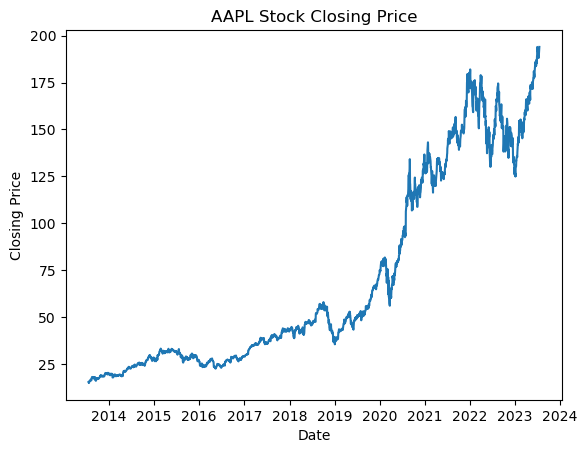

In [15]:
#AAPL(apple)
aapl = df[df["Company"] == "AAPL"]
aapl = aapl.sort_values("Date")

plt.plot(aapl["Date"], aapl["Close/Last"])
plt.title("AAPL Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

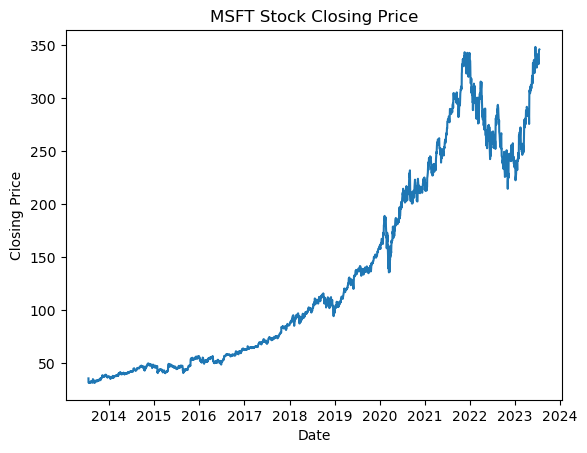

In [16]:
#msft(microsoft)
msft = df[df["Company"] == "MSFT"]
msft = msft.sort_values("Date")

plt.plot(msft["Date"], msft["Close/Last"])
plt.title("MSFT Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

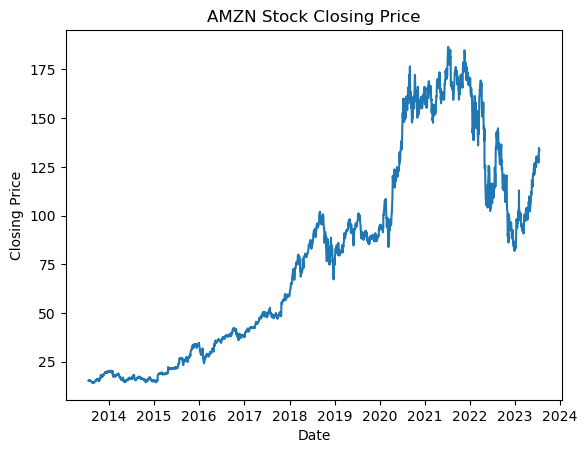

In [17]:
#amzn(amazon)
amzn = df[df["Company"] == "AMZN"]
amzn = amzn.sort_values("Date")

plt.plot(amzn["Date"], amzn["Close/Last"])
plt.title("AMZN Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

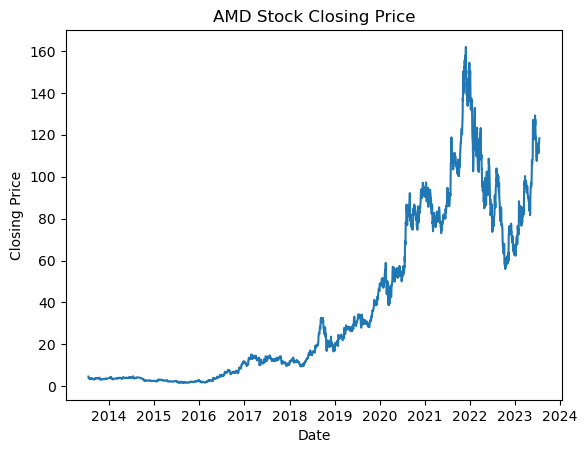

In [18]:
#AMD
amd = df[df["Company"] == "AMD"]
amd = amd.sort_values("Date")

plt.plot(amd["Date"], amd["Close/Last"])
plt.title("AMD Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

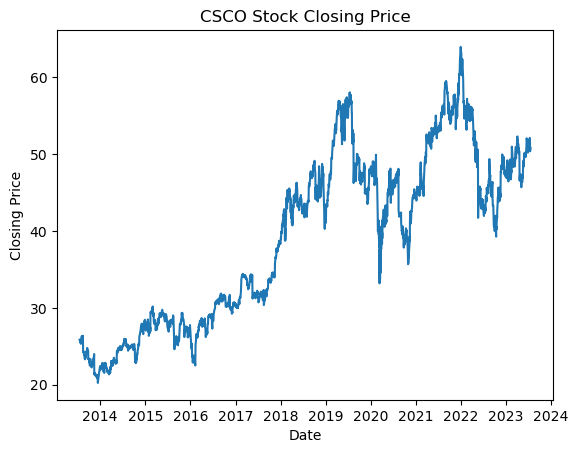

In [19]:
#CSCO(cisco)
csco = df[df["Company"] == "CSCO"]
csco = csco.sort_values("Date")

plt.plot(csco["Date"], csco["Close/Last"])
plt.title("CSCO Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

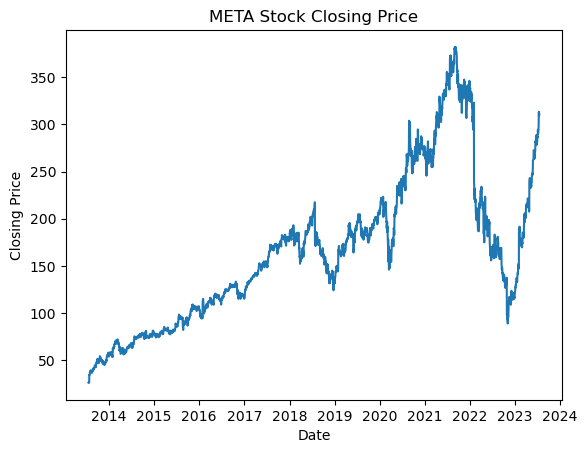

In [20]:
#META
meta = df[df["Company"] == "META"]
meta = meta.sort_values("Date")

plt.plot(meta["Date"], meta["Close/Last"])
plt.title("META Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

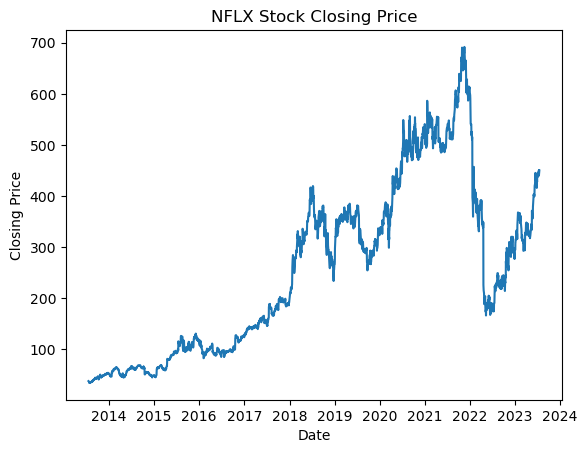

In [21]:
#NFLX(netflix)
nflx = df[df["Company"] == "NFLX"]
nflx = nflx.sort_values("Date")

plt.plot(nflx["Date"], nflx["Close/Last"])
plt.title("NFLX Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

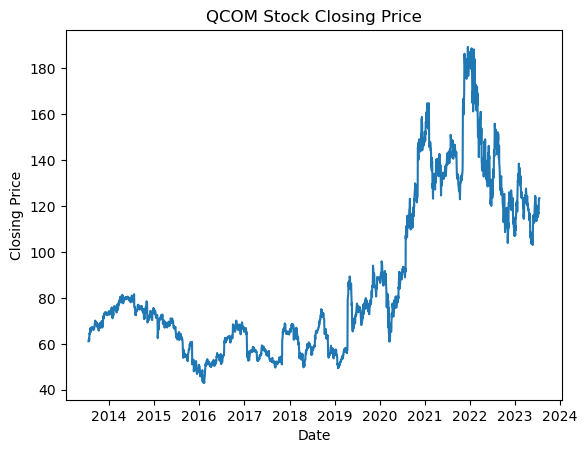

In [22]:
#Qualcomm (QCOM)
qcom = df[df["Company"] == "QCOM"]
qcom = qcom.sort_values("Date")

plt.plot(qcom["Date"], qcom["Close/Last"])
plt.title("QCOM Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

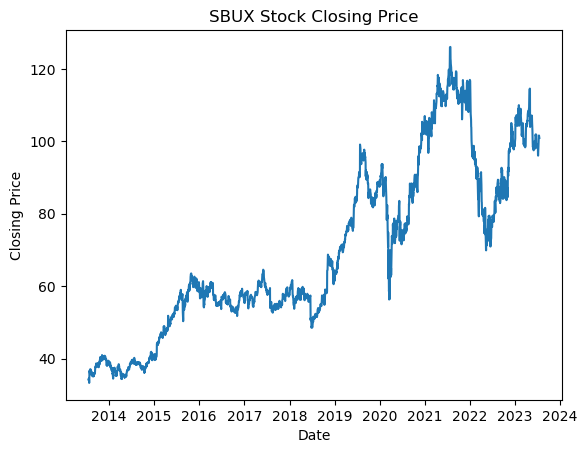

In [23]:
#Starbucks (SBUX)
sbux = df[df["Company"] == "SBUX"]
sbux = sbux.sort_values("Date")

plt.plot(sbux["Date"], sbux["Close/Last"])
plt.title("SBUX Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

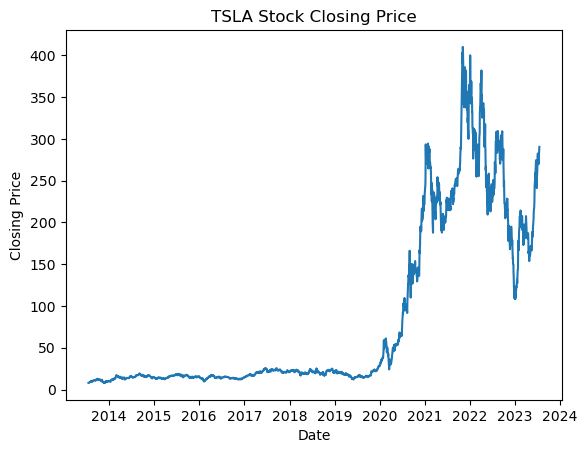

In [24]:
#Tesla (TSLA)
tsla = df[df["Company"] == "TSLA"]
tsla = tsla.sort_values("Date")

plt.plot(tsla["Date"], tsla["Close/Last"])
plt.title("TSLA Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

look at the average closing price for each company.

In [25]:
print(df.groupby("Company")["Close/Last"].mean())

Company
AAPL     70.294163
AMD      38.069080
AMZN     78.827081
CSCO     39.090075
META    165.724114
MSFT    135.610791
NFLX    256.768639
QCOM     86.945386
SBUX     69.964221
TSLA     83.265228
Name: Close/Last, dtype: float64


# Find the highest and lowest closing prices

In [26]:
print(df.groupby("Company")["Close/Last"].agg(["min", "max"]))

             min       max
Company                   
AAPL     14.9639  193.9900
AMD       1.6200  161.9100
AMZN     14.0465  186.5705
CSCO     20.2400   63.9600
META     25.8810  382.1800
MSFT     31.1520  348.1000
NFLX     34.4714  691.6900
QCOM     42.9600  189.2800
SBUX     33.3050  126.0600
TSLA      7.9353  409.9700


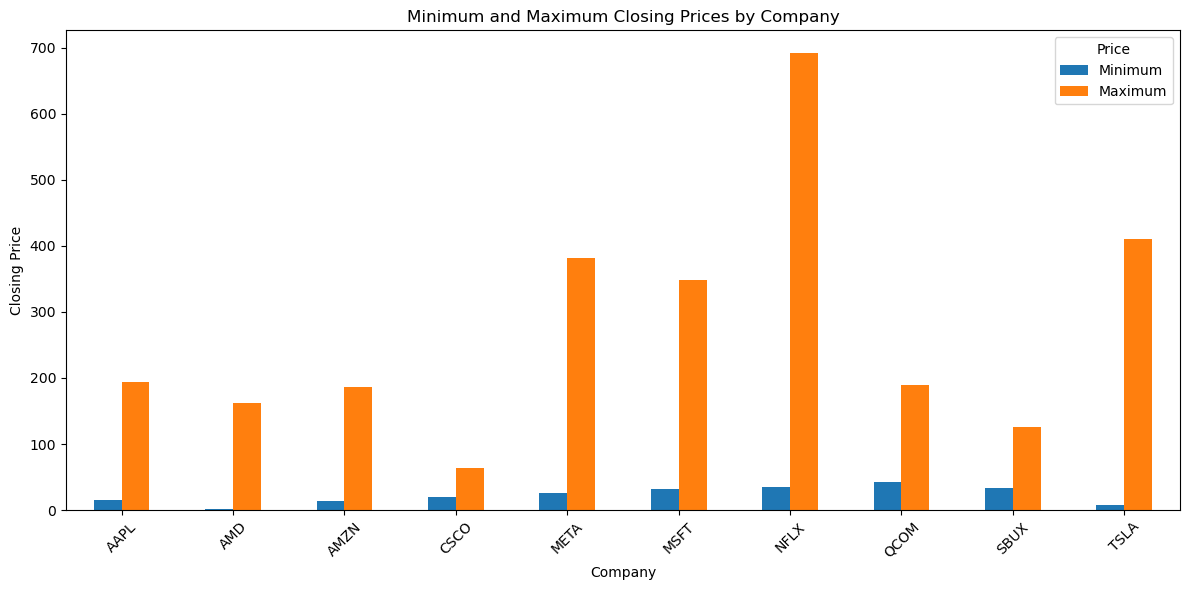

In [27]:
# Minimum and Maximum Closing Prices by Company

min_max = df.groupby("Company")["Close/Last"].agg(Minimum="min",Maximum="max")

min_max.plot(kind="bar",figsize=(12,6))
plt.title("Minimum and Maximum Closing Prices by Company")
plt.xlabel("Company")
plt.ylabel("Closing Price")
plt.xticks(rotation=45)
plt.legend(title="Price")
plt.tight_layout()
plt.show()

# Correlation is used to identify the relationship between numerical variables and understand how they change in relation to each other.

* To identify your stock market price relationship, correlation helps us understand how variables like Open, High, Low, Close/Last, and Volume are related for each company.

* Positive correlation (+1): Both variables tend to increase or decrease together.

* Negative correlation (-1): When one variable increases, the other tends to decrease.

* Zero correlation (0): There is no linear relationship between the variables.

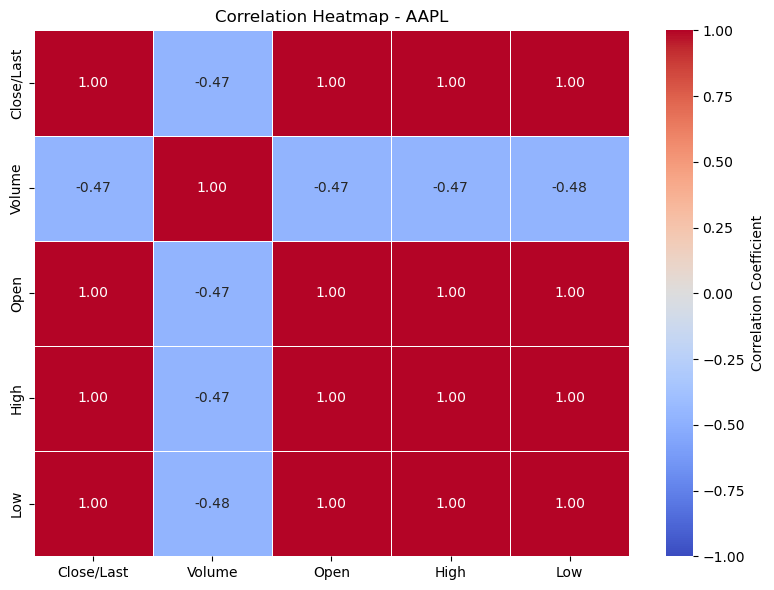

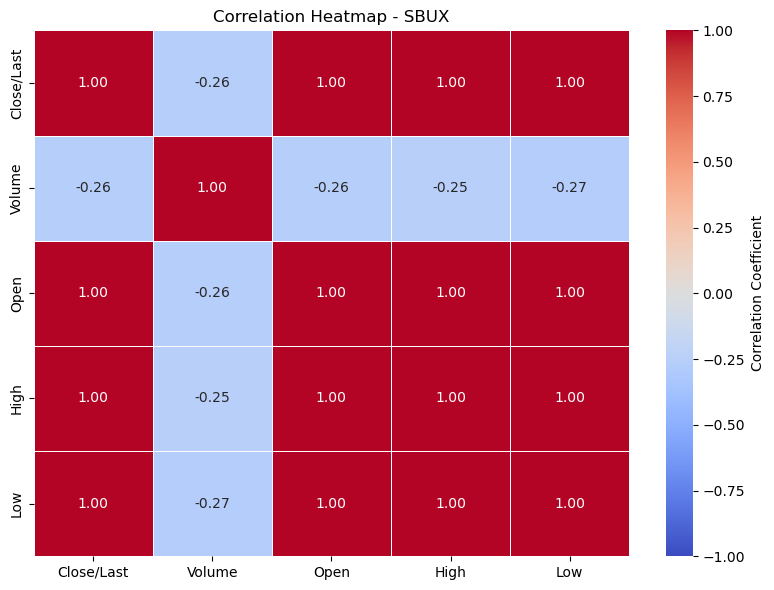

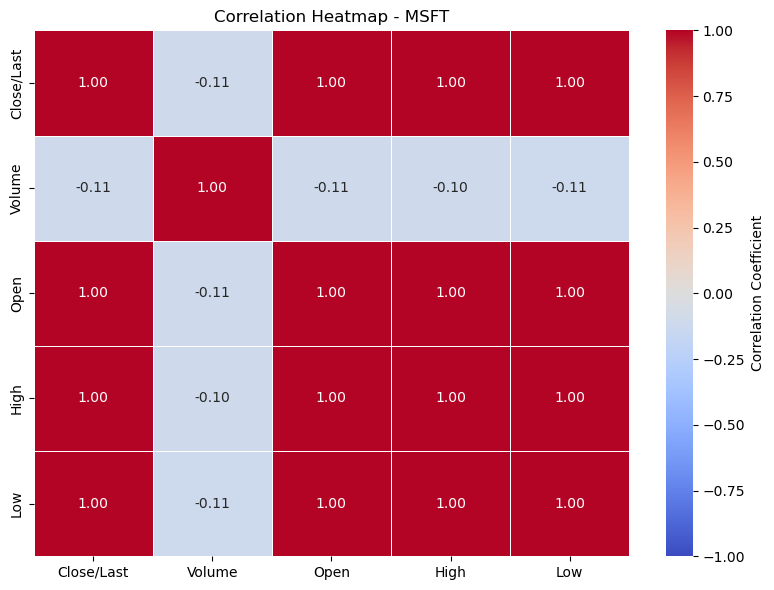

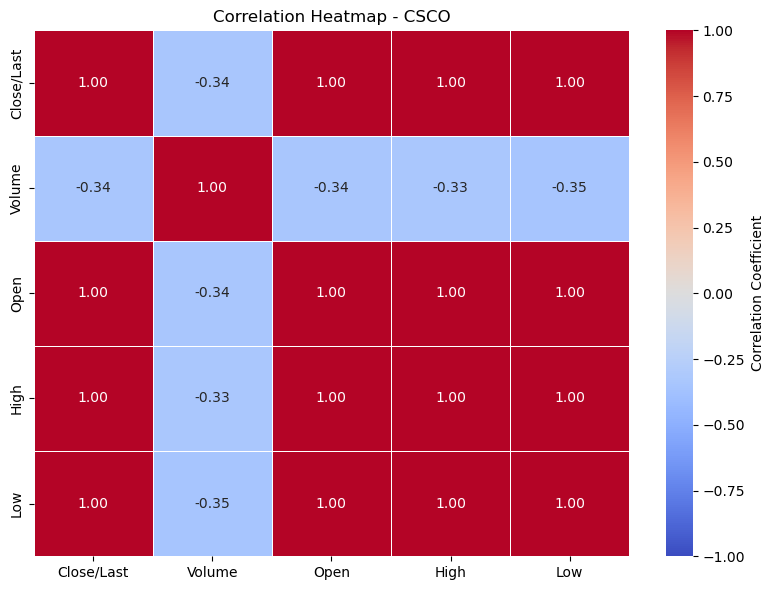

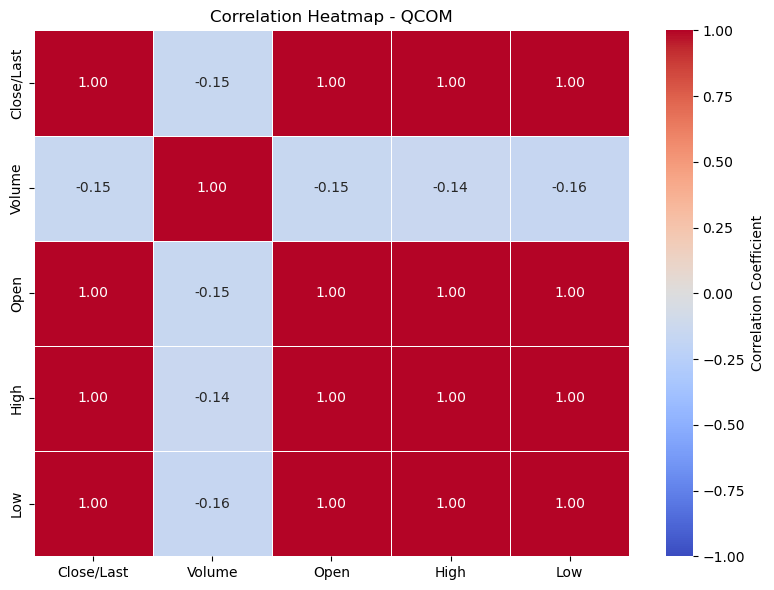

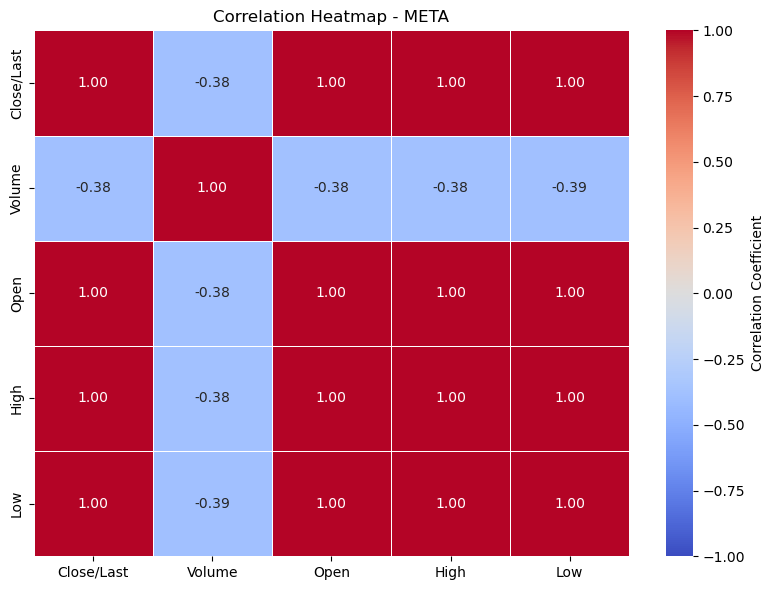

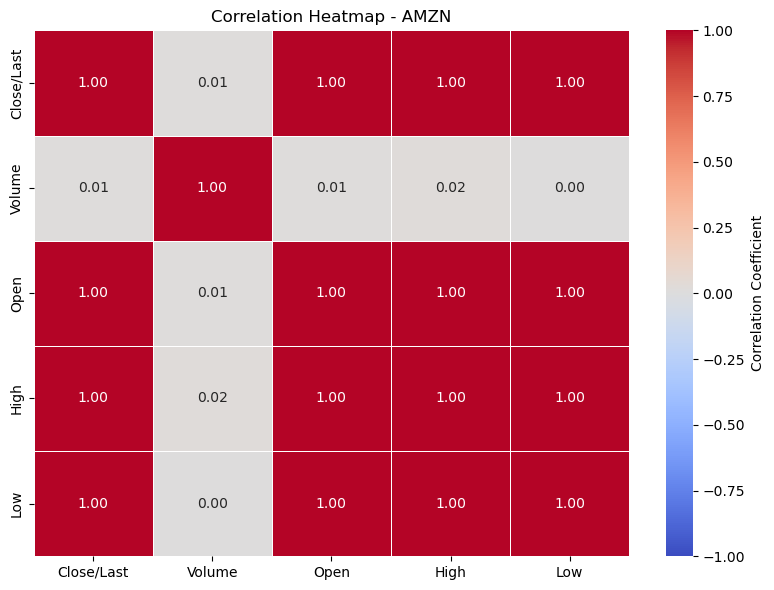

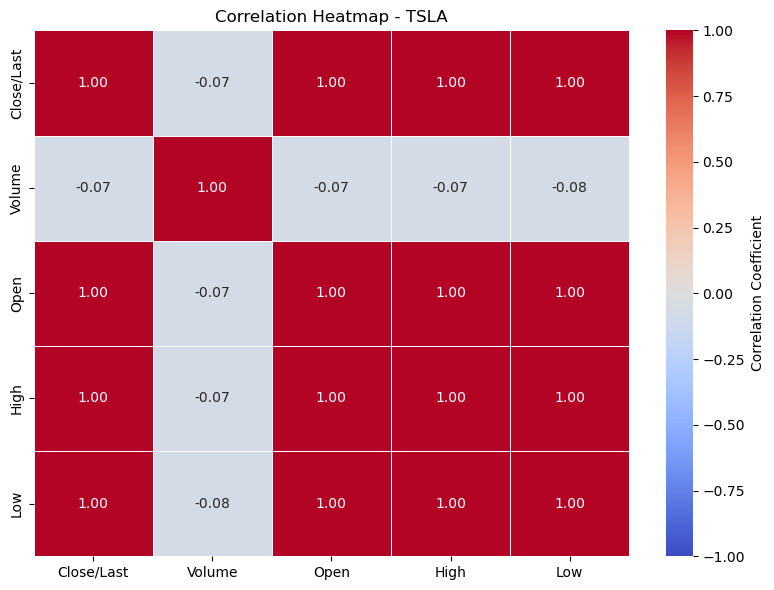

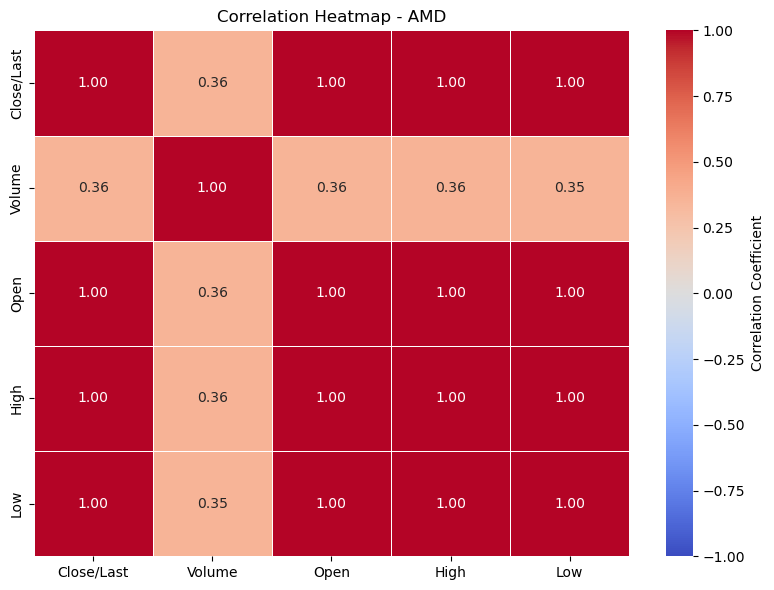

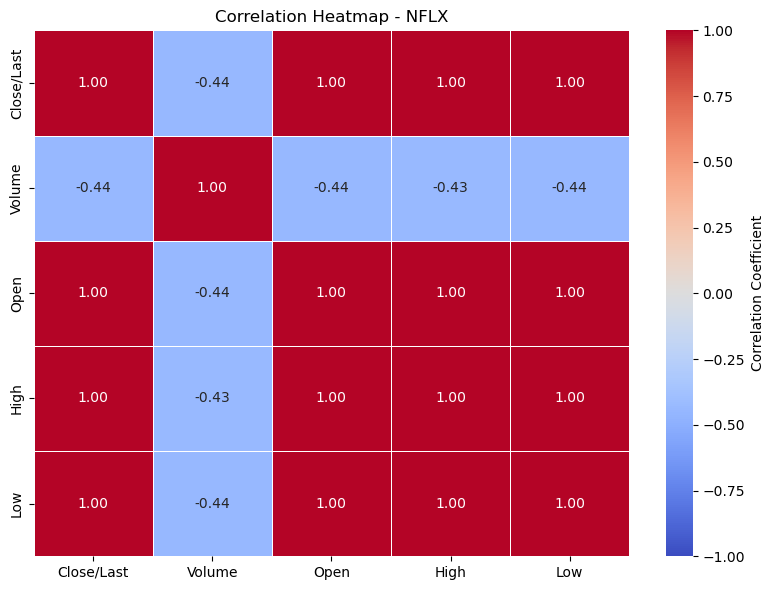

In [28]:
# Correlation plot using Heatmap

numeric_columns = ["Close/Last","Volume","Open","High","Low"]

for company in df["Company"].unique():

    company_data = df[df["Company"] == company]
    correlation_matrix = company_data[numeric_columns].corr()

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        cbar_kws={"label": "Correlation Coefficient"}

    )

    plt.title(f"Correlation Heatmap - {company}")
    plt.tight_layout()
    plt.show()


To identify  average closing price of all companies for each date and visualize it using a line graph. This helps us identify overall price trends and fluctuations over time.

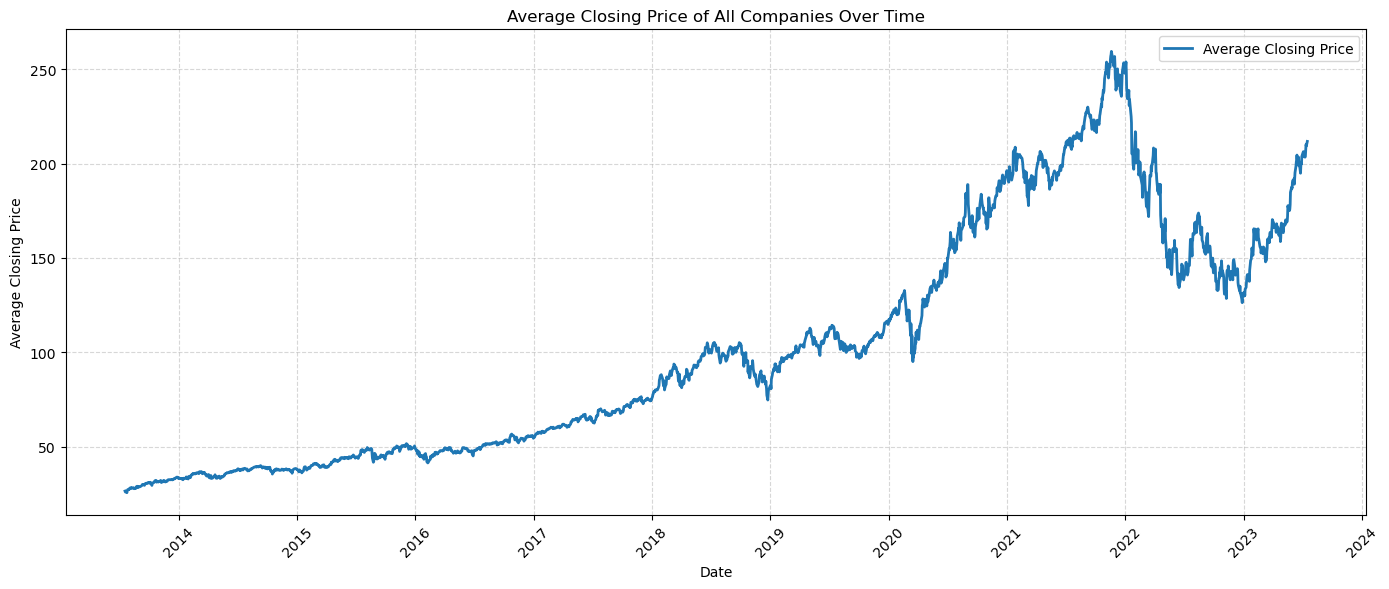

In [29]:
# Average closing price of all Companies

average_data = df.groupby("Date")["Close/Last"].mean().sort_index()

plt.figure(figsize=(14, 6))
plt.plot(average_data.index, average_data.values, linewidth=2,label="Average Closing Price")

plt.title("Average Closing Price of All Companies Over Time")
plt.xlabel("Date")
plt.ylabel("Average Closing Price")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Dummyfication** (one-hot encoding) converts categorical data into numerical columns. In our dataset, the categorical column is Company.

In [30]:
company_dummies = pd.get_dummies(
    df["Company"],
    prefix="Company",
    dtype=int
)


display(company_dummies.head())

df_dummified = pd.concat([df, company_dummies], axis=1)

print("Dataset shape before:", df.shape)
print("Dataset shape after:", df_dummified.shape)

,Company_AAPL,Company_AMD,Company_AMZN,Company_CSCO,Company_META,Company_MSFT,Company_NFLX,Company_QCOM,Company_SBUX,Company_TSLA
0,1,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0


Dataset shape before: (25160, 7)
Dataset shape after: (25160, 17)


# **Note :** In df_dummified dataset Company Variable is still there, its fine for EDA but When we Are dealing with machine learning We have to drop the column.


To identify relationships and patterns between numerical stock attributes using a pair plot, helping us understand how stock prices and trading volume vary together and identify potential outliers.

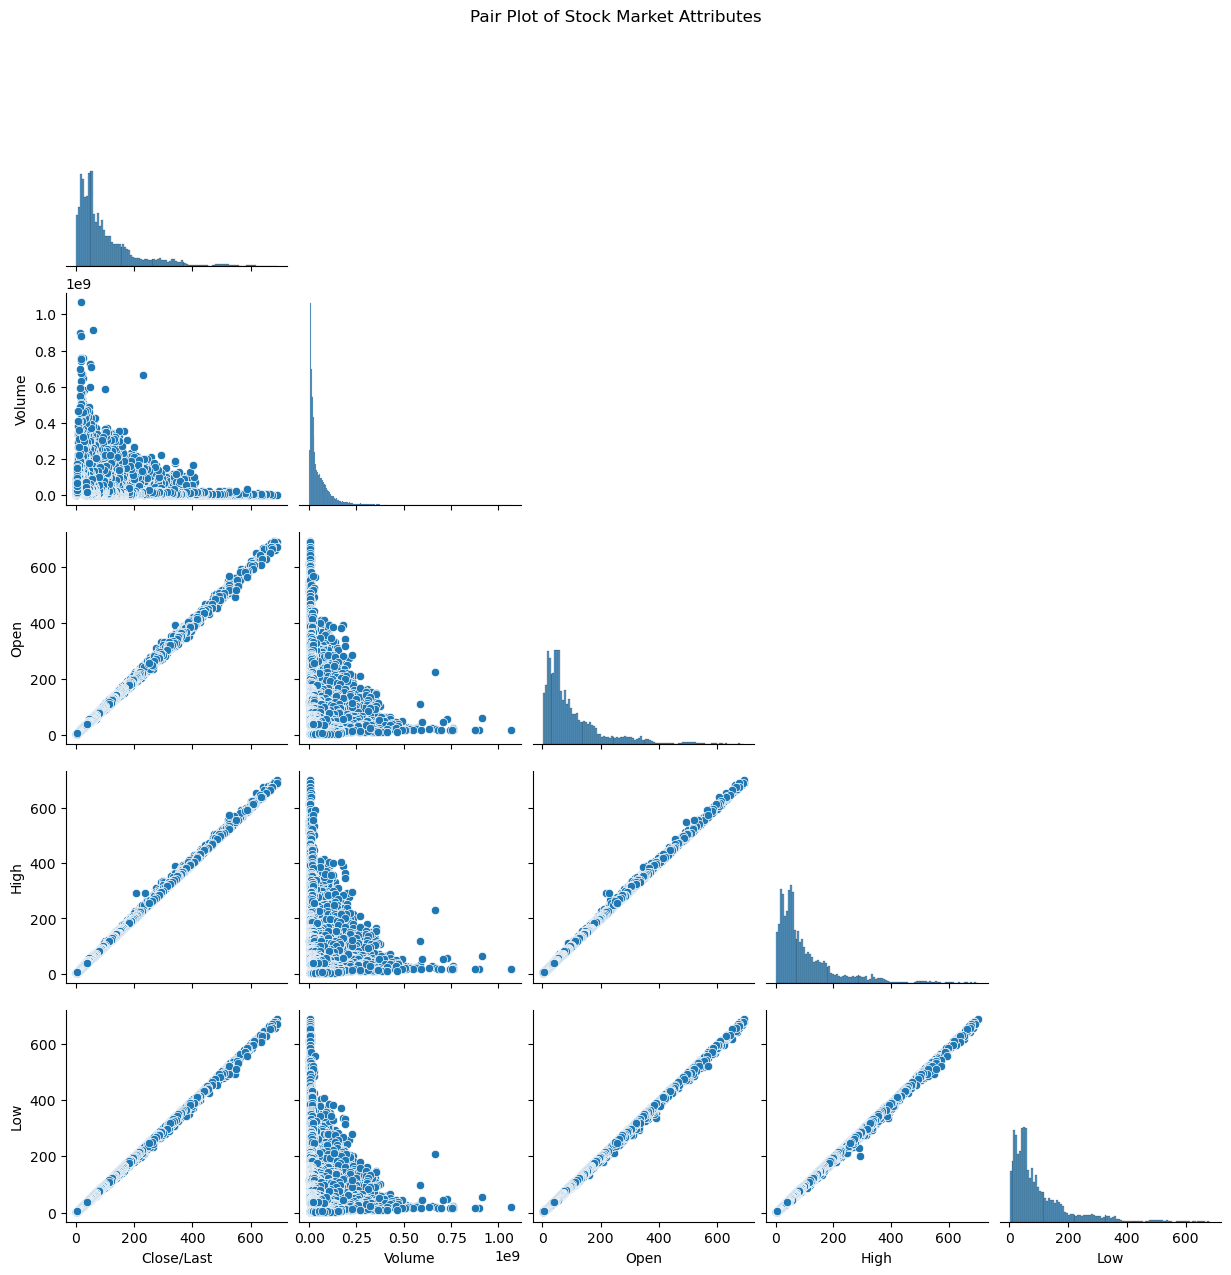

In [31]:
numerical_columns = [
    "Close/Last",
    "Volume",
    "Open",
    "High",
    "Low"
]

# Create pair plot
sns.pairplot(
    df[numerical_columns],
    diag_kind="hist",
    corner=True
)

plt.suptitle("Pair Plot of Stock Market Attributes", y=1.02)
plt.show()

To identify the total number of shares traded across all companies over time using a line graph, helping us understand trading activity and identify dates with high or low trading volumes.

We sum the Volume values for all companies on each date and plot them over time. This helps us identify dates with high or low overall trading activity.

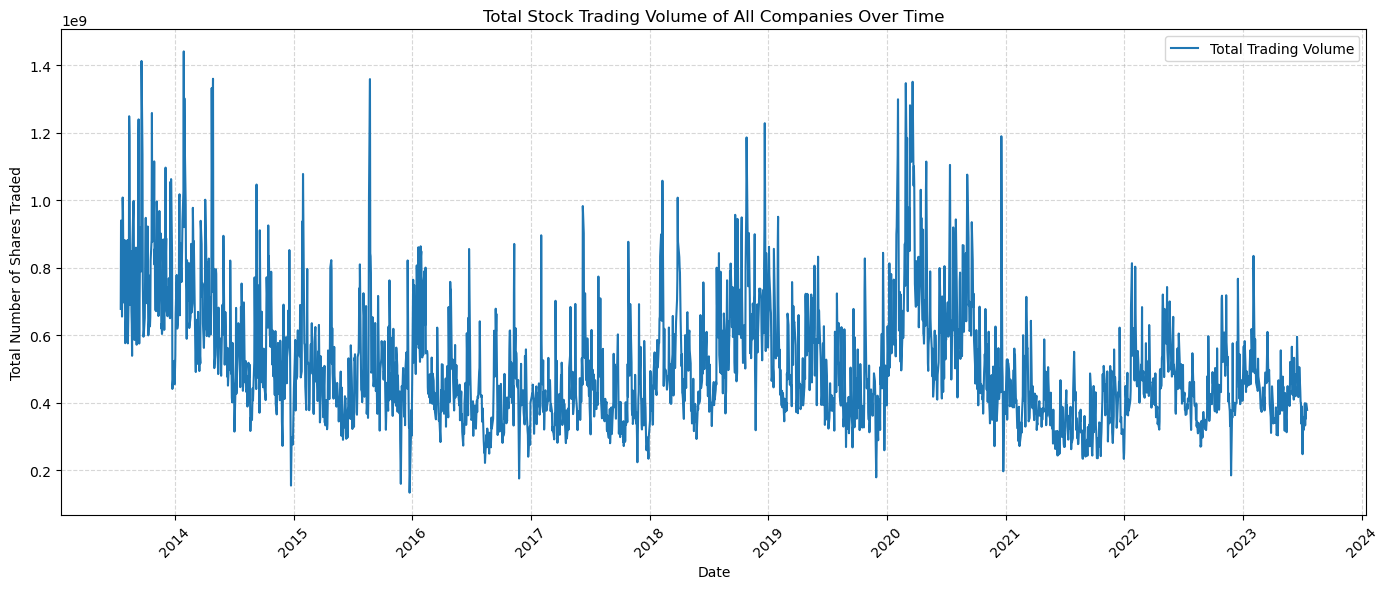

In [32]:
volume_over_time = df.groupby("Date")["Volume"].sum().sort_index()


plt.figure(figsize=(14, 6))
plt.plot(volume_over_time.index,volume_over_time.values,label = "Total Trading Volume", linewidth =1.5)

plt.title("Total Stock Trading Volume of All Companies Over Time")
plt.xlabel("Date")
plt.ylabel("Total Number of Shares Traded")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

To identify the top 5 companies with the highest total trading volume using a bar plot, helping us compare trading activity and determine which companies have the most shares traded during the dataset period.

By comparing the bars, we can identify which companies had the highest and lowest trading volumes among the top five.

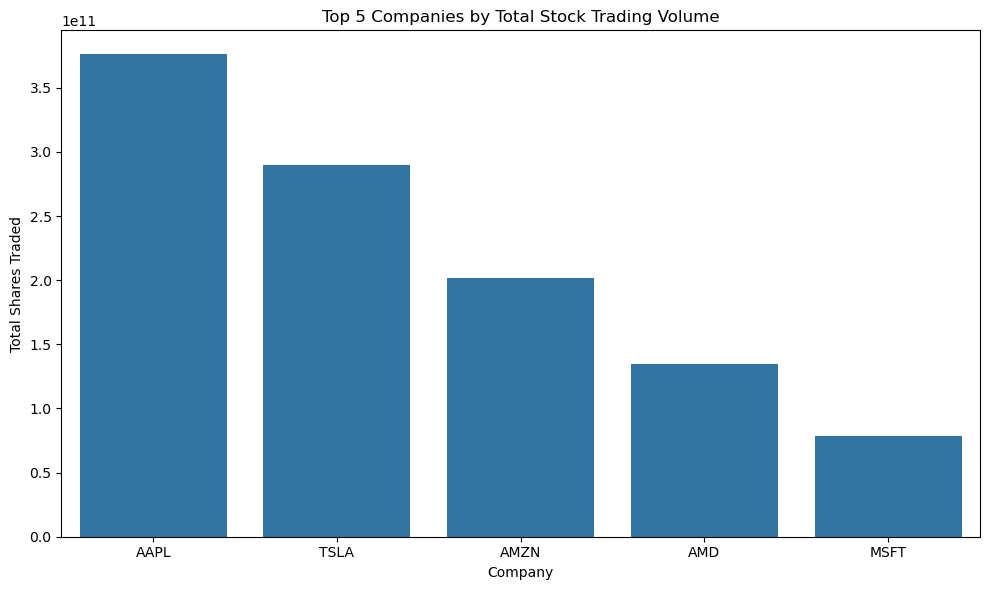

In [33]:
company_volume = df.groupby("Company")["Volume"].sum()

top_company = company_volume.sort_values(ascending=False).head(5)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_company.index, y=top_company.values)

plt.title("Top 5 Companies by Total Stock Trading Volume")
plt.xlabel("Company")
plt.ylabel("Total Shares Traded")
plt.tight_layout()
plt.show()

To compare the closing stock prices of the top 5 companies by trading volume over time, helping us identify price trends, fluctuations, and differences in stock performance.

# What we can find
- **Price trends:**  Which companies' stock prices generally increased or decreased.
- **Volatility:**  Which companies experienced larger price fluctuations.
- **Performance differences:**  How the closing prices of the five companies changed over the same period

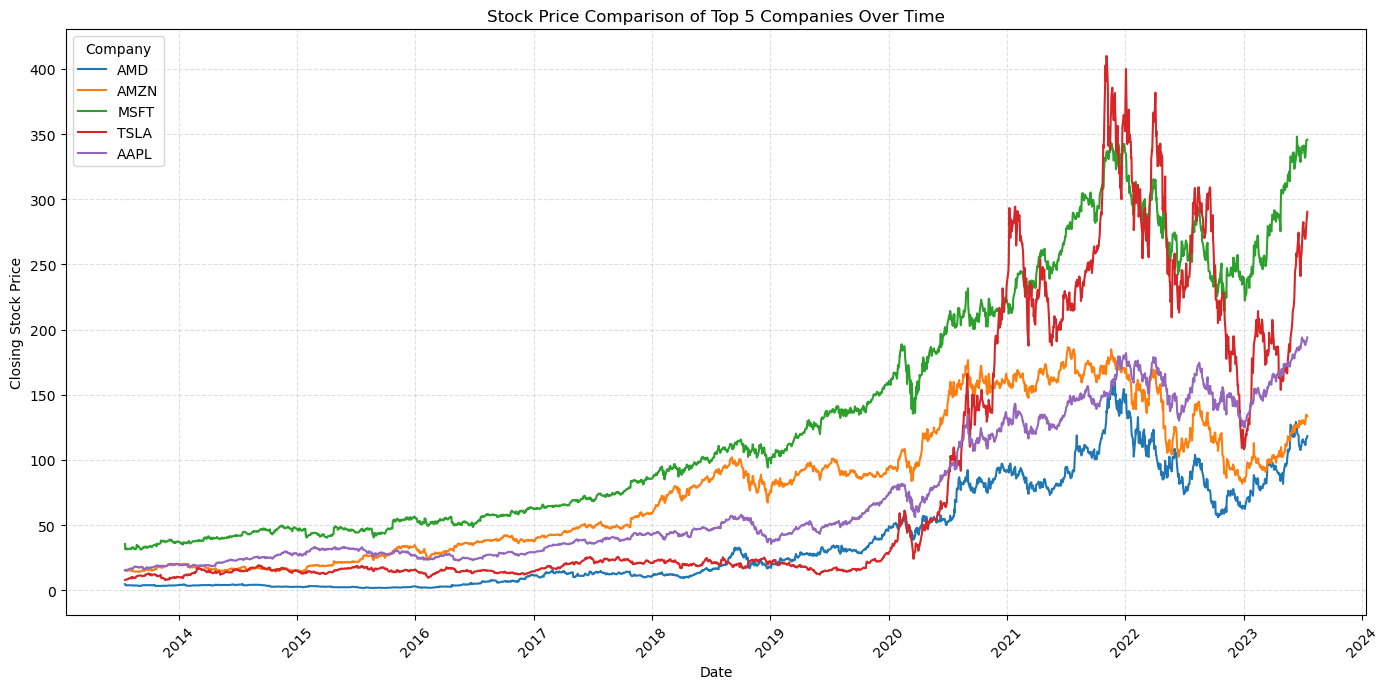

In [34]:
top_5_companies = (df.groupby("Company")["Volume"].sum().nlargest(5).index)

comparison_df = df[df["Company"].isin(top_5_companies)].copy()
comparison_df = comparison_df.sort_values("Date")

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=comparison_df,
    x="Date",
    y="Close/Last",
    hue="Company"
)

plt.title("Stock Price Comparison of Top 5 Companies Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Stock Price")
plt.legend(title="Company")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# **EDA part Completed...**